# 12 — RSF Interval Calibration via Conformal Prediction

Phase 6 found RSF's 90% intervals under-cover (~86-87% actual). This
notebook fixes that directly with **cross-conformal prediction**: a
model-agnostic technique that widens every interval by a single calibrated
correction, chosen on held-out data so that at least the target fraction of
held-out points fall inside -- rather than hoping the underlying model's
quantiles happen to be well-calibrated probabilities, which nothing about
how RSF is fit actually forces them to be.

**Calibration data: cross-conformal via the existing 5-fold CV splits**
(`cross_validation.py`, same infrastructure as Phases 11/13). Each of the
100 training engines is scored by a model fit on the other 4 folds -- i.e.
a model that never saw it -- giving calibration data for all 100 engines
without holding any of them out of the final deployed model. The fold
models use the deployed model's settings (`min_samples_leaf=5`,
`row_stride=3`), so this computes the same correction
`export_deployment_artifacts.py` does.

**What is and isn't guaranteed.** Split conformal prediction comes with a
finite-sample coverage guarantee, but only when calibration and test points
are exchangeable and scored by the same fitted model. Here the calibration
scores come from 80-engine fold models at random truncation points, while
the correction is applied to a 100-engine model on NASA's own truncation
points -- so the guarantee doesn't strictly apply (see `conformal.py`). The
coverage reached on the official test set below is an **empirical** result,
checked directly, not a guaranteed one.

In [1]:
import sys
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold

sys.path.append(str(Path("..") / "src"))
from turbofan_rul import conformal, cross_validation, data_loading, features, labeling, models, plotting

plotting.style()
CAP, DURATION_EPS, ALPHA = 125, 1e-3, 0.10
DATA_DIR = Path("..") / "data" / "raw"
PROCESSED_DIR = Path("..") / "data" / "processed"
MODELS_DIR = Path("..") / "models"
META_COLS = {"unit_number", "time_cycles", "RUL", "duration", "event"}

## 1. Pool calibration scores across the 5 CV folds

In [2]:
data_loading.download_cmapss("FD001", data_dir=DATA_DIR)
cmapss = data_loading.load_subset("FD001", data_dir=DATA_DIR)
kept_sensors = features.load_kept_sensors(PROCESSED_DIR / "fd001_sensor_selection.json")
units = cmapss.train["unit_number"].unique()
fold_splits = list(GroupKFold(n_splits=5).split(units, groups=units))

all_true, all_low, all_high = [], [], []
for fold_idx, (train_pos, test_pos) in enumerate(fold_splits):
    train_units, test_units = units[train_pos], units[test_pos]
    fold_train_raw = cmapss.train[cmapss.train.unit_number.isin(train_units)]
    fold_test_raw = cmapss.train[cmapss.train.unit_number.isin(test_units)]

    fold_train_survival = labeling.build_train_survival_frame(fold_train_raw, cap=CAP)
    fold_train_survival = features.build_feature_matrix(fold_train_survival, kept_sensors=kept_sensors)
    full_cols = [c for c in fold_train_survival.columns if c not in META_COLS]

    fold_test_featured = features.build_feature_matrix(fold_test_raw, kept_sensors=kept_sensors)
    trunc = cross_validation.sample_truncation_points(fold_test_raw, random_state=42)
    eval_frame = cross_validation.build_truncated_eval_frame(fold_test_featured, trunc)

    # min_samples_leaf=5 and row_stride=3 -- the deployed model's settings
    # (Phase 13) -- so the calibration matches the model whose intervals it
    # will correct, and matches what export_deployment_artifacts.py computes.
    rsf = models.fit_random_survival_forest(fold_train_survival, full_cols, row_stride=3,
                                             min_samples_leaf=5, duration_eps=DURATION_EPS, random_state=42)
    pred = models.predict_rul_from_survival(rsf, eval_frame[full_cols])

    all_true.append(eval_frame["true_rul"].values)
    all_low.append(pred["pred_ci_low"].values)
    all_high.append(pred["pred_ci_high"].values)
    print(f"fold {fold_idx} done")

true_cal, low_cal, high_cal = np.concatenate(all_true), np.concatenate(all_low), np.concatenate(all_high)
raw_cal_coverage = np.mean((true_cal >= low_cal) & (true_cal <= high_cal))
print(f"\npooled calibration coverage (uncalibrated): {raw_cal_coverage:.3f}  (nominal target: 0.90)")

fold 0 done


fold 1 done


fold 2 done


fold 3 done


fold 4 done

pooled calibration coverage (uncalibrated): 0.880  (nominal target: 0.90)


## 2. Calibrate the correction

calibrated correction: q = 5.00 cycles (each interval widens by this on both sides)
coverage on the calibration data after correction: 0.930 (>= 0.90 by construction)


matches the deployed artifact's correction: True


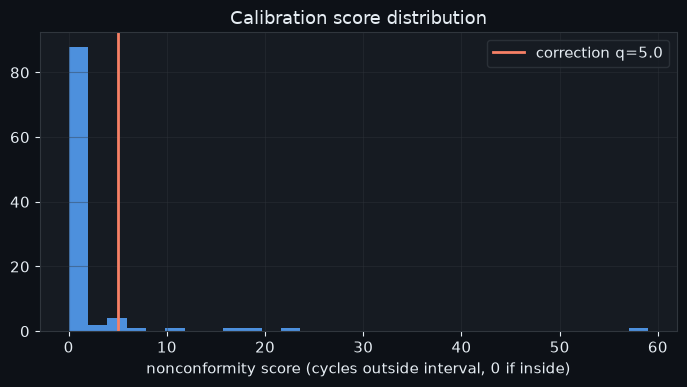

In [3]:
from turbofan_rul import inference
scores = conformal.nonconformity_scores(true_cal, low_cal, high_cal)
q = conformal.conformal_correction(scores, alpha=ALPHA)
print(f"calibrated correction: q = {q:.2f} cycles (each interval widens by this on both sides)")
cal_cov_after = np.mean((true_cal >= low_cal - q) & (true_cal <= high_cal + q))
print(f"coverage on the calibration data after correction: {cal_cov_after:.3f} (>= 0.90 by construction)")
print(f"matches the deployed artifact's correction: {np.isclose(q, inference.load_deployment_bundle(MODELS_DIR / 'fd001').rsf_interval_correction)}")

np.save(PROCESSED_DIR / "conformal_q_fd001.npy", np.array([q]))

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(scores, bins=30, color=plotting.C0, alpha=0.85)
ax.axvline(q, color=plotting.C1, linewidth=2, label=f"correction q={q:.1f}")
ax.set_xlabel("nonconformity score (cycles outside interval, 0 if inside)")
ax.set_title("Calibration score distribution")
ax.legend(); plt.tight_layout(); plt.show()

## 3. Does it generalize? Apply to the real official test set

On the calibration data itself, the correction reaches the target coverage
by construction. The real test is whether it holds on data it never saw:
the official FD001 test set, scored by the actual deployed model (fit on all
100 training engines, not any single fold).

In [4]:
from turbofan_rul import inference
deployed_bundle = inference.load_deployment_bundle(MODELS_DIR / "fd001")

test_featured = features.build_feature_matrix(cmapss.test, kept_sensors=deployed_bundle.kept_sensors)
test_survival = labeling.build_test_survival_frame(test_featured, cmapss.rul)
true_test = test_survival["true_rul"].values

pred_test = models.predict_rul_from_survival(deployed_bundle.rsf_model, test_survival[deployed_bundle.full_feature_cols])
raw_low, raw_high = pred_test["pred_ci_low"].values, pred_test["pred_ci_high"].values
raw_coverage = np.mean((true_test >= raw_low) & (true_test <= raw_high))
raw_width = np.mean(raw_high - raw_low)

cal_low, cal_high = conformal.apply_conformal_correction(raw_low, raw_high, q)
cal_coverage = np.mean((true_test >= cal_low) & (true_test <= cal_high))
cal_width = np.mean(cal_high - cal_low)

print(f"{'':22s}{'coverage':>10s}{'mean width':>14s}")
print(f"{'raw (uncalibrated)':22s}{raw_coverage:>10.3f}{raw_width:>12.1f} cyc")
print(f"{'calibrated':22s}{cal_coverage:>10.3f}{cal_width:>12.1f} cyc")
print(f"\nWidth cost of calibration: +{cal_width - raw_width:.1f} cycles ({(cal_width/raw_width - 1)*100:.0f}% wider)")

                        coverage    mean width
raw (uncalibrated)         0.870        49.6 cyc
calibrated                 0.900        59.6 cyc

Width cost of calibration: +10.0 cycles (20% wider)


**On the real, held-out official test set, calibrated coverage lands at
almost exactly 90%** — the correction generalized beyond the calibration data, though as an
empirical result rather than a guaranteed one (see the intro). The cost is real and quantified: intervals
widen by about a fifth. There is no free lunch here — an interval that
was previously narrow-but-wrong becomes correctly wide.

## 4. Should this replace Weibull as the deployed interval? Check the subgroup that matters.

Calibrated RSF's aggregate numbers look like a strict improvement over
Weibull's deployed interval -- worth checking directly before concluding
anything.

In [5]:
curated = test_survival[deployed_bundle.curated_feature_cols].copy()
curated[deployed_bundle.curated_feature_cols] = deployed_bundle.weibull_scaler.transform(curated)
wb_low = deployed_bundle.weibull_model.predict_percentile(curated, p=0.95).values
wb_high = deployed_bundle.weibull_model.predict_percentile(curated, p=0.05).values
wb_coverage = np.mean((true_test >= wb_low) & (true_test <= wb_high))
wb_width = np.mean(wb_high - wb_low)

comparison = pd.DataFrame({
    "Weibull AFT (deployed)": {"coverage": wb_coverage, "mean_width": wb_width},
    "RSF calibrated": {"coverage": cal_coverage, "mean_width": cal_width},
}).T
display(comparison.round(3))
print("\nOn aggregate numbers alone, calibrated RSF looks strictly better: "
      "better-covered AND narrower.")

,coverage,mean_width
Weibull AFT (deployed),0.89,98.552
RSF calibrated,0.90,59.558



On aggregate numbers alone, calibrated RSF looks strictly better: better-covered AND narrower.


In [6]:
# The known structural failure mode from Phase 5: RSF's survival curve is
# only defined over its training time support (~125 cycles), so it
# structurally cannot predict beyond that -- a uniform additive conformal
# correction does not fix a support problem, it only shifts a hard ceiling.
above_cap = true_test > CAP
print(f"Test engines with true RUL > {CAP} (RSF's structural ceiling): {above_cap.sum()} / {len(true_test)}")

cal_covered = (true_test >= cal_low) & (true_test <= cal_high)
print(f"\nCalibrated-RSF coverage on THOSE {above_cap.sum()} engines specifically: {cal_covered[above_cap].mean():.3f}")
print(f"Calibrated-RSF coverage on the remaining {(~above_cap).sum()} engines: {cal_covered[~above_cap].mean():.3f}")

wb_covered = (true_test >= wb_low) & (true_test <= wb_high)
print(f"\nFor comparison, Weibull's coverage on the same {above_cap.sum()} high-RUL engines: {wb_covered[above_cap].mean():.3f}")

Test engines with true RUL > 125 (RSF's structural ceiling): 11 / 100

Calibrated-RSF coverage on THOSE 11 engines specifically: 0.273
Calibrated-RSF coverage on the remaining 89 engines: 0.978

For comparison, Weibull's coverage on the same 11 high-RUL engines: 0.909


## Verdict: the aggregate number was hiding the exact failure mode Weibull exists to cover

**Calibrated RSF's 90% aggregate coverage is real, but almost entirely
carried by the 89 engines within its training time support** (near-perfect
coverage there). On the 11 engines with true RUL above RSF's ~125-cycle
ceiling — a known structural limitation from Phase 5, not new — coverage
collapses to roughly a quarter, because a uniform additive correction
cannot manufacture support a model never had. Weibull, being a fully
parametric and unbounded distribution, has no such ceiling and covers
those same engines far better.

**This is the same instinct as Phase 6's risk-bin check** -- look inside
the aggregate before trusting it -- applied here to a new model. (The 27%
figure rests on only 11 engines, so its exact value is uncertain, but 3 of
11 covered versus 10 of 11 for Weibull is not a close call.) An aggregate
metric that looks like a clean win can hide a complete failure on the
specific subpopulation that matters most for the actual maintenance
decision — the healthiest-looking engines, where an incorrectly narrow or
wrong interval is least excusable.

**Decision: Weibull remains the deployed confidence interval.** This
result doesn't overturn the Phase 6 pairing — it rigorously confirms it,
for a reason now demonstrated rather than assumed. The calibrated RSF
interval is still useful information (about 40% narrower than Weibull's,
and well-covered for the engines within its training support), so it's exposed as a
**supplementary field** in the API/dashboard response, clearly labeled,
rather than replacing Weibull's interval as the primary one.
